In [2]:
import os
import glob
import json
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as cl
from mpl_toolkits.axes_grid1 import make_axes_locatable
import seaborn as sns
import pandas as pd
from collections import defaultdict
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    f1_score,
    cohen_kappa_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
)


In [3]:
def plot_confusion_matrix(
        y_true: np.ndarray,
        y_pred: np.ndarray,
        ax: plt.Axes,
        labels: list,
        fontsize: int = 10,
        colorbar: bool = True
    ):
    # Include normalized and absolute numbers in the plot 
    # cm_norm = confusion_matrix(y_true, y_pred,normalize='true')
    cm_abs = confusion_matrix(y_true, y_pred,normalize=None)
    cm_norm = cm_abs/cm_abs.sum(axis=1, keepdims=True)
    
    # Create base image and colobar
    im = ax.imshow(cm_norm, cmap=plt.cm.Blues, vmin=0, vmax=1)
    if colorbar:
        # cbar = ax.figure.colorbar(im, ax=ax)
        # cbar.ax.tick_params(labelsize=fontsize)
        divider = make_axes_locatable(ax)
        cax = divider.append_axes("right", size="2%", pad=0.05)
        plt.colorbar(im, cax=cax)
    
    cmap_min, cmap_max = im.cmap(0), im.cmap(1.0)
    thresh = (cm_norm.max() + cm_norm.min()) / 2.0
    # Use numpy to generate all combinations of i,j indices
    for i, j in np.ndindex(cm_abs.shape):
        # print text with appropriate color depending on background
        color = cmap_max if cm_norm[i, j] < thresh else cmap_min
        
        # Plot both percentage and absolute numbers
        text_cm_norm = f'{round(cm_norm[i, j]*100, 1)}%'
        text_cm_abs = f'{round(cm_abs[i, j])}'

        ax.text(j, i-0.03, text_cm_norm, ha="center", va="bottom", color=color, fontsize=fontsize)
        ax.text(j, i+0.03, text_cm_abs, ha="center", va="top", color=color, fontsize=fontsize)

    return im

def h5_to_dict(h5_path):
    data = defaultdict(dict)
    with h5py.File(h5_path, 'r') as f:
        data['start_time'] = f.attrs['start_time']

        if 'ahi' in f.attrs.keys():
            data['ahi'] = f.attrs['ahi']
        
        if np.any([f'{stage}_hours' in f.attrs.keys() for stage in ['wake', 'n1', 'n2', 'n3', 'rem']]):
            stages = {
                'wake': 0,
                'n1': 0,
                'n2': 0,
                'n3': 0,
                'rem': 0,
                'missing': 0,
            }

            for stage in stages.keys():
                if f'{stage}_hours' in f.attrs.keys():
                    stages[stage] = f.attrs[f'{stage}_hours']
            data['stages_hours'] = stages
        
        data['accelerometry'] = np.array(f['data/accelerometry'])
        data['hypnogram'] = np.array(f['annotations/hypnogram'])

    return data

def safe_cw_auc(targets, scores, mode = 'ovo', count_lim = 2):
    unique_targets, counts = np.unique(targets, return_counts=True)
    unique_targets = unique_targets[counts > count_lim]
    cw_auc = np.full(scores.shape[-1], np.nan)
    if len(unique_targets) == 1:
        return cw_auc
    for k in unique_targets:
        if mode == 'ovo':
            cw_auc[k] = 0
            for l in unique_targets:
                if l == k: continue
                tmp_mask = np.logical_or(targets == k, targets == l)
                tmp_targets = targets[tmp_mask]
                tmp_scores = scores[tmp_mask, k]
                cw_auc_kvl = roc_auc_score(tmp_targets == k,tmp_scores)
                cw_auc[k] += cw_auc_kvl/(len(unique_targets -1))
        elif mode == 'ovr':
            cw_auc[k] = roc_auc_score(targets == k, scores[:, k])
        else:
            raise "Mode must be ovo or ovr"
    return cw_auc

def safe_cw_pr_re_f1(targets, preds, num_classes, count_lim = 2):
    unique_targets, counts = np.unique(targets, return_counts=True)

    # Target count filter
    count_filt = np.full(num_classes, np.nan)
    count_filt[unique_targets[counts > count_lim]] = 1 

    # Calculate scores (results will only include present targets)
    cw_prec = precision_score(targets, preds, average=None, zero_division=np.nan)
    cw_rec = recall_score(targets, preds, average=None, zero_division=np.nan)
    cw_f1 = f1_score(targets, preds, average=None, zero_division=np.nan)

    # Initialize NaN arrays to fill to make sure all possible targets are representet
    cw_prec_array = np.full(num_classes, np.nan)
    cw_rec_array = np.full(num_classes, np.nan)
    cw_f1_array = np.full(num_classes, np.nan)

    # Fill in NaN arrays
    for i, k in enumerate(unique_targets):
        cw_prec_array[k] = cw_prec[i] * count_filt[i]
        cw_rec_array[k] = cw_rec[i] * count_filt[i]
        cw_f1_array[k] = cw_f1[i] * count_filt[i]

    return cw_prec_array, cw_rec_array, cw_f1_array

def calc_sleep_summary_metrics(stages, label_map):
    metrics = {}
    # Calculate TST
    sleep = stages != label_map['wake']
    tst = (sleep).sum()
    metrics['tst'] = float(tst)
    
    try:
        # Calculate SOL (first consecutive 3-epoch sleep window)
        # [[sleep, False, False],
        # [False, sleep, False],
        # [False, False, sleep]]
        sleep_shifted = np.stack([
            np.append(sleep, [False, False]),
            np.insert(np.append(sleep, [False]), 0, [False]),
            np.insert(sleep, 0, [False, False]),
        ])
        sol = np.argwhere(sleep_shifted.all(axis=0)).min()
        metrics['sol'] = float(sol)

        # Calculate WASO, how to handle missing?
        # Trim back from the last index if it is wake
        # Find last index of sleep 
        last_sleep = np.argwhere(stages != label_map['wake']).max() + 1
        waso = (stages[sol: last_sleep] == label_map['wake']).sum()
        metrics['waso'] = float(waso)
    except:
        metrics['sol'] = np.nan
        metrics['waso'] = np.nan
    # Calculate SE
    # se = (stages[sol: last_sleep] != label_map['wake']).sum() / (last_sleep - sol)
    se = (stages != label_map['wake']).sum() / len(stages)
    metrics['se'] = float(se)

    # Calculate REM
    rem = (stages == ss_label_map['rem']).sum()
    metrics['rem'] = float(rem)
    
    # Calculate Deep
    deep = (stages == ss_label_map['deep']).sum()
    metrics['deep'] = float(deep)

    # Calculate Light
    light = (stages == ss_label_map['light']).sum()
    metrics['light'] = float(light)

    # Calculate NREM
    nrem = light + deep
    metrics['nrem'] = float(nrem)

    return metrics


In [4]:
ss_labels_name = 'light_deep_rem'
ss_label_map = {
    'deep': 0,
    'light': 1,
    'rem': 2,
    'wake': 3,
    'missing': -9,
}
# ss_label_map_inv = {val: key for key, val in ss_label_map.items()}
ss_label_map_inv = {val: key for key, val in ss_label_map.items() if val != -9}
ss_label_order = ['wake', 'light', 'deep', 'rem']
ss_label_names = ['Wake', 'Light', 'Deep', 'REM']

ss_colormap = {
    'wake': 'tab:red',
    'Wake': 'tab:red',
    'light': 'tab:orange',
    'Light': 'tab:orange',
    'deep': 'tab:blue',
    'Deep': 'tab:blue',
    'rem': 'tab:green',
    'REM': 'tab:green',
}
ss_case_map = {
    'wake':'Wake',
    'light': 'Light',
    'deep': 'Deep',
    'rem': 'REM',
}

dset_map = {
    'newcastle_left': 'Newcastle',
    'newcastle_right': 'Newcastle',
    'stages': 'STAGES',
    'dreamt': 'DREAMT',
    'tbi': 'TBI',
    'amazfit': 'Health',
    'sleepaccel': 'SleepAccel',
}

In [ ]:
## Subject-wise performance metrics
cw_precs = defaultdict(list)
cw_recalls = defaultdict(list)
cw_f1s = defaultdict(list)

cw_aucs = defaultdict(list)
roc_curves = defaultdict(list)
soft_preds_all = []
targets_all = []
preds_all = []

macro_results = defaultdict(list)
summary_diffs = defaultdict(list)
summary_means = defaultdict(list)
exp_i = []
subject_i = []
dataset_i = []

lin_path = '/oak/stanford/groups/mignot/projects/actigraphy_fm/results/bwm_mae_external'
lstmc_path = '/oak/stanford/groups/mignot/projects/actigraphy_fm/results/bwm_mae_lstmc_external'

experiments = [('Linear', lin_path), ('LSTM-C', lstmc_path)]
for exp_name, experiment_dir in experiments:
    for dataset in os.scandir(experiment_dir):
        for sub_dir in os.scandir(dataset):
            subject_i.append(os.path.basename(sub_dir))
            dataset_i.append(os.path.basename(dataset))
            exp_i.append(exp_name)

            missing_idx = ss_label_map['missing']

            scores = np.load(os.path.join(sub_dir.path + '/soft_preds.npy'))
            targets = np.load(os.path.join(sub_dir.path + '/targets.npy'))

            scores = scores[targets != missing_idx]
            targets = targets[targets != missing_idx]
            
            # Excluded NaNs due to signal dropout in AccelSleep
            nan_mask = np.isnan(scores).any(-1)
            scores = scores[~nan_mask]
            targets = targets[~nan_mask]

            # Get hard predictions
            preds = scores.argmax(axis=-1)
            
            soft_preds_all.append(scores)
            targets_all.append(targets)
            preds_all.append(preds)
            
            unique_targets, counts = np.unique(targets, return_counts=True)
            unique_preds, pred_counts = np.unique(preds, return_counts=True)

            ## Subject-wise class-wise scores
            # Precision, Recall, and F1
            cw_pr, cw_re, cw_f1 = safe_cw_pr_re_f1(targets, preds, num_classes=scores.shape[-1], count_lim=3)
            
            # Manually compute binary AUC for each label present (NaN for non-valid)
            cw_auc = safe_cw_auc(targets, scores, mode='ovr', count_lim=3)

            for k in range(scores.shape[-1]):
                cw_aucs[ss_label_map_inv[k]].append(float(cw_auc[k]))
                cw_precs[ss_label_map_inv[k]].append(float(cw_pr[k]))
                cw_recalls[ss_label_map_inv[k]].append(float(cw_re[k]))
                cw_f1s[ss_label_map_inv[k]].append(float(cw_f1[k]))

            # Class-wise ROC curves
            for k in range(scores.shape[-1]):
                roc = roc_curve(targets, scores[:,k], pos_label=k)
                roc_curves[ss_label_map_inv[k]].append(roc)
            
            ## Subject-wise macro averages
            mac_prec = precision_score(targets, preds, average='macro', zero_division=np.nan)
            mac_rec = recall_score(targets, preds, average='macro', zero_division=np.nan)
            mac_f1 = f1_score(targets, preds, average='macro', zero_division=np.nan)
            kappa = cohen_kappa_score(targets, preds)
            macro_results['Precision'].append(mac_prec)
            macro_results['Recall'].append(mac_rec)
            macro_results['F1'].append(mac_f1)
            macro_results['Kappa'].append(kappa)
            macro_results['AUC'].append(np.nanmean(cw_auc))

            pred_metrics = calc_sleep_summary_metrics(preds, ss_label_map)
            target_metrics = calc_sleep_summary_metrics(targets, ss_label_map)
            summary_diff = {
                f'{key}': pred_metrics[key] - target_metrics[key]
                for key
                in pred_metrics.keys()
            }
            summary_mean = {
                f'{key}': (pred_metrics[key] + target_metrics[key])/2 
                for key 
                in pred_metrics.keys()
            }
            for key in summary_diff.keys():
                summary_diffs[key].append(summary_diff[key])
                summary_means[key].append(summary_mean[key])
            

macro_results = pd.DataFrame(data=macro_results)
cw_aucs = pd.DataFrame(data=cw_aucs)
cw_precs = pd.DataFrame(data=cw_precs)
cw_recalls = pd.DataFrame(data=cw_recalls)
cw_f1s = pd.DataFrame(data=cw_f1s)
summary_means = pd.DataFrame(data=summary_means)
summary_diffs = pd.DataFrame(data=summary_diffs)
for col in summary_means.columns:
    if col == 'se':
        factor = 100 # fraction to %
    else:
        factor = 0.5 # 30s epoch to minutes
    summary_diffs[col] = summary_diffs[col] * factor
    summary_means[col] = summary_means[col] * factor

In [ ]:
# Plot median class-wise AUC curves with IQR
import matplotlib
sns.set_context("paper")
sns.set_style('ticks')
matplotlib.rcParams['font.size'] = 7
matplotlib.rcParams['font.family'] = 'sans-serif'

fig, axes = plt.subplots(len(experiments),2, dpi=600, figsize=(7.1,6), layout='constrained')
# axes = axes.ravel()
for i, (model, _) in enumerate(experiments):
    print(model)
    col = axes[:,i]
    ax = col[0]
    for label in ss_label_order:
        tpr = []
        fpr_new = np.linspace(0,1,500) 
        curves = np.array(roc_curves[label], dtype='O')[np.array(exp_i)==model]
        for curve in curves:
            if len(curve[0]) < 4 or np.isnan(curve[0]).any():
                continue
            curve[2][0] = 1
            tpr.append(np.interp(fpr_new, curve[0], curve[1]))

        tpr = np.array(tpr)
        med_tpr = np.nanmedian(tpr,axis=0)
        med_auc_calc = round(med_tpr.mean(),2)
        q75 = np.nanquantile(tpr, 0.75, axis=0)
        q75_auc_calc = round(q75.mean(),2)
        q25 = np.nanquantile(tpr, 0.25, axis=0)
        q25_auc_calc = round(q25.mean(),2)
        if label == ss_label_order[0]:
            # q75_handle = ax.plot(fpr_new[:1], q75[:1], color='gray', ls='t'.', label=f'Q75')
            q25_handle = ax.plot(fpr_new[:1], q25[:1], color='gray', ls=':', label=f'IQR')

        ax.plot(fpr_new, q75, color=ss_colormap[label], ls=':', alpha=0.75)# label=f'{label}, q75 AUC {q75_auc_calc}')
        ax.plot(fpr_new, q25, color=ss_colormap[label], ls=':', alpha=0.75)# label=f'{label}, q25 AUC {q25_auc_calc}')
        
        ax.plot(fpr_new, med_tpr, color=ss_colormap[label], label=f'{ss_case_map[label]}, AUC = {med_auc_calc}')
        # ax.fill_between(fpr_new, q25, q75, color=ss_colormap[label], alpha=0.1)

    ax.plot(fpr_new, fpr_new, color='black', ls='--')
    ax.grid(visible=False)
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.set_title(f'{model}\n\nMedian ROC Curves')
    legend1 = ax.legend(markerfirst=False, frameon=False)

    # Plot Subject-wise class wise scores
    cw_f1s['score'] = 'F1'
    cw_precs['score'] = 'Precision'
    cw_recalls['score'] = 'Recall'
    cw_aucs['score'] = 'AUROC'
    cw_scores = pd.concat([cw_f1s, cw_precs, cw_recalls, cw_aucs], axis=0)
    cw_scores = cw_scores.melt(id_vars=['score'], value_vars=['wake', 'light', 'deep', 'rem'])
    cw_scores['variable'] = cw_scores['variable'].map(ss_case_map)

    ax = sns.boxplot(
        cw_scores, x='score', y='value', hue='variable', ax = col[1],
        showfliers=False, saturation=0.75, palette = ss_colormap,
        order = ['Precision', 'Recall', 'F1', 'AUROC'],
    )
    # sns.stripplot(cw_scores, x='score', y='value', hue='variable', dodge=True, legend=False),
    ax.legend(title='', ncols=4, handletextpad = 0.4, columnspacing=0.8, mode='expand', bbox_to_anchor=(0,1,1,1), loc='lower left')
    ax.set_ylabel('Metric Value')
    ax.set_xlabel('')

    # Add alphabetic ordering
    for i, ax in enumerate(axes.ravel()):
        ax.annotate(
            f'{chr(97+i)}',
            xy=(-0.1, 1.1), xycoords='axes fraction',
            xytext=(+0.5, -0.5), textcoords='offset fontsize', fontweight='bold',
            fontsize='large', verticalalignment='bottom', horizontalalignment='right',# fontfamily='verdana',
            bbox=dict(facecolor='none', edgecolor='none', pad=3.0)
        )
plt.show()


In [ ]:
# Epoch by epoch ROC
fig, axes = plt.subplots(2, 2, dpi=600, figsize=(6.5,6.3), layout='constrained')
for i, (model, _) in enumerate(experiments):
    col = axes[:, i]
    # Plot class_wise AUCS
    preds = np.concatenate(list(np.array(preds_all,dtype='O')[np.array(exp_i)==model]))
    targets = np.concatenate(list(np.array(targets_all,dtype='O')[np.array(exp_i)==model]))
    soft_preds = np.concatenate(list(np.array(soft_preds_all,dtype='O')[np.array(exp_i)==model]))
    ax = col[0]
    cw_auc = roc_auc_score(targets, soft_preds, average=None, multi_class='ovr', labels=[0,1,2,3])
    for k in range(soft_preds.shape[-1]):
        roc = roc_curve(targets, soft_preds[:,k], pos_label=k)
        ax.plot(roc[0], roc[1], label=f'{ss_label_map_inv[k]}, AUC={round(cw_auc[k],2)}')
    ax.plot(roc[2], roc[2], ls='--',color='black')
    ax.set_title(f'{model}\n\nEpoch-by-epoch ROC curves')
    ax.set_xlabel('FPR')
    ax.set_ylabel('TPR')
    ax.legend()

    # Epoch-by-epoch confusion matrix
    # Switch label orders 
    idx_dict = {}
    for place, tag in enumerate(ss_label_order):
        idx_dict[place] = (
            targets == ss_label_map[tag],
            preds == ss_label_map[tag],
        )
    for place, (label_idx, pred_idx) in idx_dict.items():
        targets[label_idx] = place
        preds[pred_idx] = place

    ## Confusion Matrix
    targets[targets == 2] = 1
    preds[preds == 2] = 1
    cm_abs = confusion_matrix(targets, preds, normalize=None)
    cm_norm = cm_abs/cm_abs.sum(axis=1, keepdims=True)
    # Create combined annotation matrix
    annot = np.empty_like(cm_abs).astype(str)
    for r in range(cm_abs.shape[0]):
        for c in range(cm_abs.shape[1]):
            annot[r, c] = f"{cm_norm[r, c]*100:.1f}%\n{cm_abs[r, c]}"
    ax = sns.heatmap(
        cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, ax=col[1],
        square=True, cbar=False, #linewidths=0.2, linecolor='black', clip_on=False,
        xticklabels=['Wake', 'NREM', 'REM'], yticklabels=['Wake', 'NREM', 'REM'],# annot_kws={'fontsize':7}
        # xticklabels=ss_label_names, yticklabels=ss_label_names,# annot_kws={'fontsize':7}
    )
    for _, spine in ax.spines.items():
        spine.set_visible(True)

    ax.tick_params(rotation = 45)
    ax.set_ylabel('Observed')
    for label in ax.get_yticklabels():
        label.set_verticalalignment('center')
    ax.set_xlabel('Predicted')
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('center')
    
    ax.set_title(f'{model}, F1={round(f1_score(targets,preds,average='macro'),2)}')

    # Add alphabetic ordering
    for i, ax in enumerate(axes.ravel()):
        ax.annotate(
            f'{chr(97+i)}',
            xy=(-0.1, 1.1), xycoords='axes fraction',
            xytext=(+0.5, -0.5), textcoords='offset fontsize', fontweight='bold',
            fontsize='large', verticalalignment='bottom', horizontalalignment='right',# fontfamily='verdana',
            bbox=dict(facecolor='none', edgecolor='none', pad=3.0)
        )

In [36]:
## Subject-wise performance metrics
cw_precs = defaultdict(list)
cw_recalls = defaultdict(list)
cw_f1s = defaultdict(list)

cw_aucs = defaultdict(list)
roc_curves = defaultdict(list)
soft_preds_all = []
targets_all = []
preds_all = []

macro_results = defaultdict(list)
summary_diffs = defaultdict(list)
summary_means = defaultdict(list)
exp_i = []
subject_i = []
dataset_i = []

ext_path = '/oak/stanford/groups/mignot/projects/actigraphy_fm/results/bwm_mae_external'
int_path = '/oak/stanford/groups/mignot/projects/actigraphy_fm/results/bwm_mae_internal'
ext2_path = '/oak/stanford/groups/mignot/projects/actigraphy_fm/results/bwm_mae_external_2'

experiments = [('Internal', int_path), ('External', ext_path), ('External2', ext2_path)]
for exp_name, experiment_dir in experiments:
    for dataset in os.scandir(experiment_dir):
        for sub_dir in os.scandir(dataset):
            subject_i.append(os.path.basename(sub_dir))
            dataset_i.append(os.path.basename(dataset))
            exp_i.append(exp_name)

            missing_idx = ss_label_map['missing']

            scores = np.load(os.path.join(sub_dir.path + '/soft_preds.npy'))
            targets = np.load(os.path.join(sub_dir.path + '/targets.npy'))

            scores = scores[targets != missing_idx]
            targets = targets[targets != missing_idx]
            
            # Excluded NaNs due to signal dropout in AccelSleep
            nan_mask = np.isnan(scores).any(-1)
            scores = scores[~nan_mask]
            targets = targets[~nan_mask]

            # Get hard predictions
            preds = scores.argmax(axis=-1)
            
            soft_preds_all.append(scores)
            targets_all.append(targets)
            preds_all.append(preds)
            
            unique_targets, counts = np.unique(targets, return_counts=True)
            unique_preds, pred_counts = np.unique(preds, return_counts=True)

            ## Subject-wise class-wise scores
            # Precision, Recall, and F1
            cw_pr, cw_re, cw_f1 = safe_cw_pr_re_f1(targets, preds, num_classes=scores.shape[-1], count_lim=3)
            
            # Manually compute binary AUC for each label present (NaN for non-valid)
            cw_auc = safe_cw_auc(targets, scores, mode='ovr', count_lim=3)

            for k in range(scores.shape[-1]):
                cw_aucs[ss_label_map_inv[k]].append(float(cw_auc[k]))
                cw_precs[ss_label_map_inv[k]].append(float(cw_pr[k]))
                cw_recalls[ss_label_map_inv[k]].append(float(cw_re[k]))
                cw_f1s[ss_label_map_inv[k]].append(float(cw_f1[k]))

            # Class-wise ROC curves
            for k in range(scores.shape[-1]):
                roc = roc_curve(targets, scores[:,k], pos_label=k)
                roc_curves[ss_label_map_inv[k]].append(roc)
            
            ## Subject-wise macro averages
            mac_prec = precision_score(targets, preds, average='macro', zero_division=np.nan)
            mac_rec = recall_score(targets, preds, average='macro', zero_division=np.nan)
            mac_f1 = f1_score(targets, preds, average='macro', zero_division=np.nan)
            kappa = cohen_kappa_score(targets, preds)
            macro_results['Precision'].append(mac_prec)
            macro_results['Recall'].append(mac_rec)
            macro_results['F1'].append(mac_f1)
            macro_results['Kappa'].append(kappa)
            macro_results['AUC'].append(np.nanmean(cw_auc))

            pred_metrics = calc_sleep_summary_metrics(preds, ss_label_map)
            target_metrics = calc_sleep_summary_metrics(targets, ss_label_map)
            summary_diff = {
                f'{key}': pred_metrics[key] - target_metrics[key]
                for key
                in pred_metrics.keys()
            }
            summary_mean = {
                f'{key}': (pred_metrics[key] + target_metrics[key])/2 
                for key 
                in pred_metrics.keys()
            }
            for key in summary_diff.keys():
                summary_diffs[key].append(summary_diff[key])
                summary_means[key].append(summary_mean[key])
            

macro_results = pd.DataFrame(data=macro_results)
cw_aucs = pd.DataFrame(data=cw_aucs)
cw_precs = pd.DataFrame(data=cw_precs)
cw_recalls = pd.DataFrame(data=cw_recalls)
cw_f1s = pd.DataFrame(data=cw_f1s)
summary_means = pd.DataFrame(data=summary_means)
summary_diffs = pd.DataFrame(data=summary_diffs)
for col in summary_means.columns:
    if col == 'se':
        factor = 100 # fraction to %
    else:
        factor = 0.5 # 30s epoch to minutes
    summary_diffs[col] = summary_diffs[col] * factor
    summary_means[col] = summary_means[col] * factor

/home/groups/mignot/nielsl/environments/torch_surv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/groups/mignot/nielsl/environments/torch_surv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/groups/mignot/nielsl/environments/torch_surv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/groups/mignot/nielsl/environments/torch_surv/lib/python3.12/site-packages/sklearn/metrics/_ranking.py:1188: UndefinedMetricWarning: No positive samples in y_true, true positive value should be meaningless
  warnings.warn(
/home/groups/mignot/nielsl/environments/torch_surv/lib/python3.12/site-packages/sklearn/

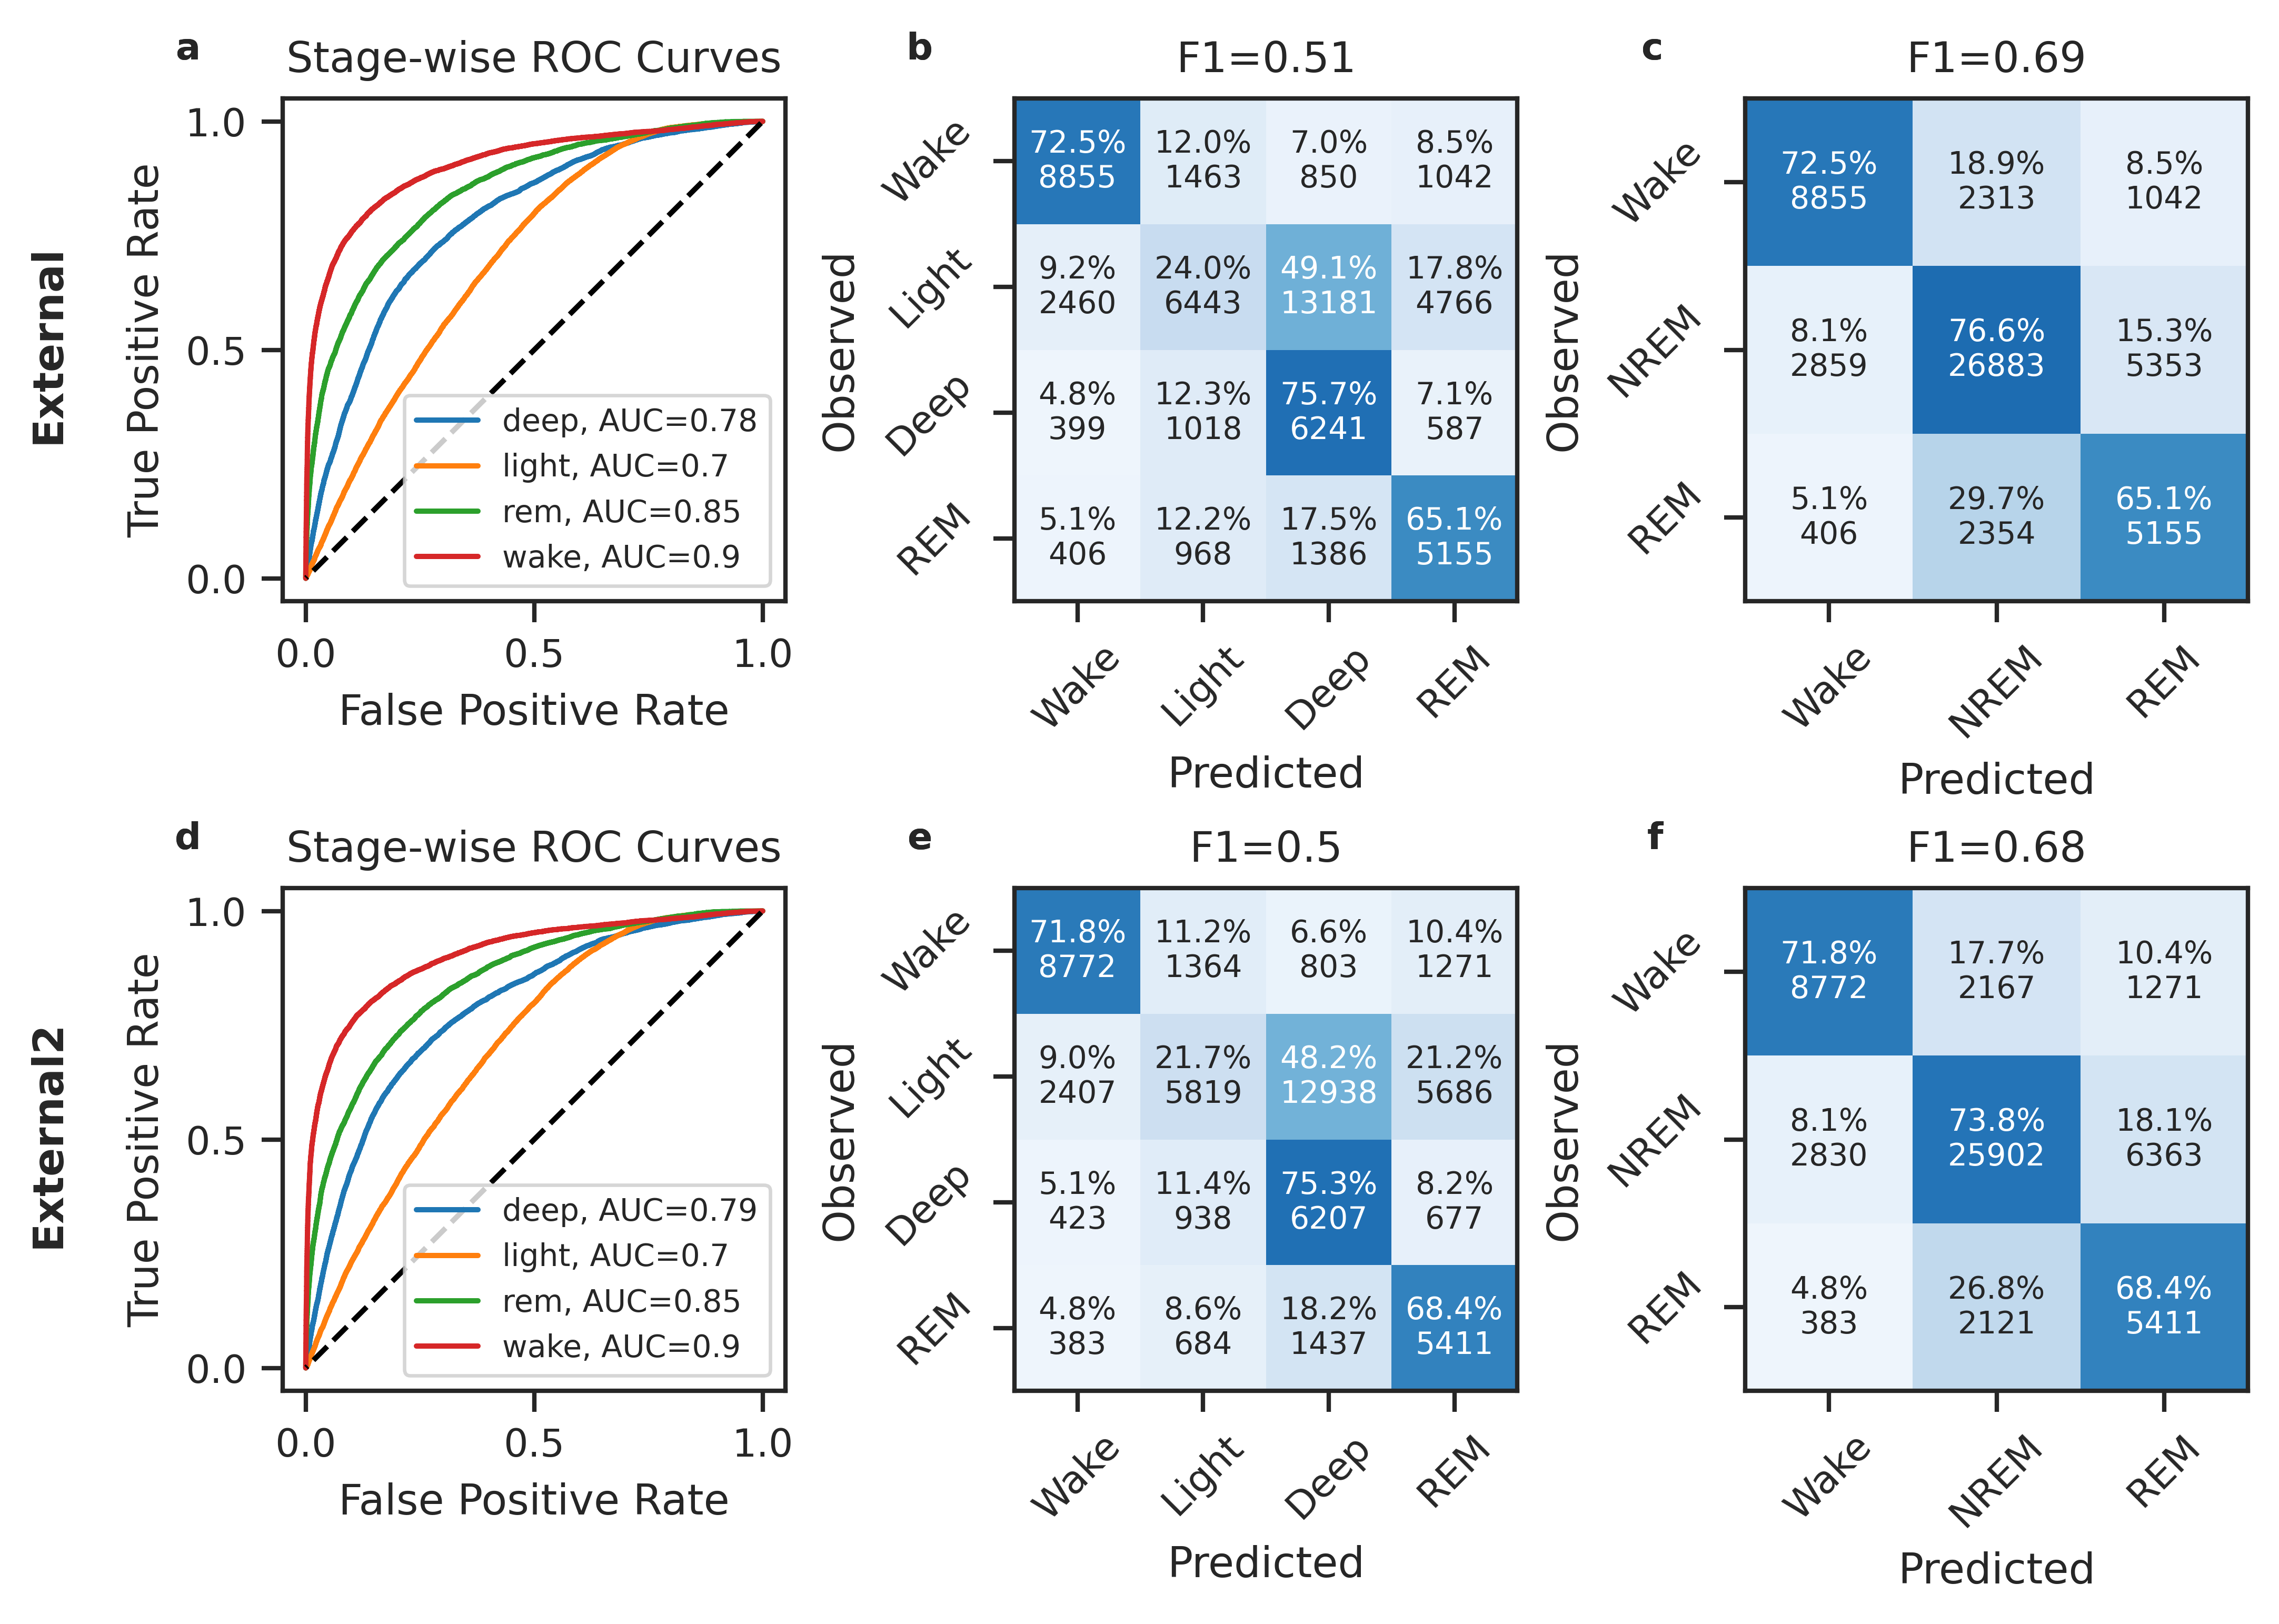

In [37]:
# Plot class-wise AUC curves and 4- and 3- class confusion matrices
import matplotlib
sns.set_context("paper")
sns.set_style('ticks')
matplotlib.rcParams['font.size'] = 7
matplotlib.rcParams['font.family'] = 'sans-serif'

fig, axes = plt.subplots(2, 3, dpi=600, figsize=(7.1,5), layout='constrained')
for i, (model, _) in enumerate(experiments[1:]):
     # Plot class_wise AUCS
    preds = np.concatenate(list(np.array(preds_all,dtype='O')[np.array(exp_i)==model]))
    targets = np.concatenate(list(np.array(targets_all,dtype='O')[np.array(exp_i)==model]))
    soft_preds = np.concatenate(list(np.array(soft_preds_all,dtype='O')[np.array(exp_i)==model]))
    ax = axes[i, 0]
    cw_auc = roc_auc_score(targets, soft_preds, average=None, multi_class='ovr', labels=[0,1,2,3])
    for k in range(soft_preds.shape[-1]):
        roc = roc_curve(targets, soft_preds[:,k], pos_label=k)
        ax.plot(roc[0], roc[1], label=f'{ss_label_map_inv[k]}, AUC={round(cw_auc[k],2)}')
    ax.plot(roc[2], roc[2], ls='--',color='black')
    ax.set_title(f'Stage-wise ROC Curves')
    ax.set_yticks([0, 0.5, 1])
    ax.set_xticks([0, 0.5, 1])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel(r'$\bf{' + model + '}$' + '\n\nTrue Positive Rate')
    ax.set_aspect('equal')
    ax.legend(fontsize=7)

    # Epoch-by-epoch confusion matrix
    # Switch label orders 
    idx_dict = {}
    for place, tag in enumerate(ss_label_order):
        idx_dict[place] = (
            targets == ss_label_map[tag],
            preds == ss_label_map[tag],
        )
    for place, (label_idx, pred_idx) in idx_dict.items():
        targets[label_idx] = place
        preds[pred_idx] = place

    ## Four-class confusion
    cm_abs = confusion_matrix(targets, preds, normalize=None)
    cm_norm = cm_abs/cm_abs.sum(axis=1, keepdims=True)
    # Create combined annotation matrix
    annot = np.empty_like(cm_abs).astype(str)
    for r in range(cm_abs.shape[0]):
        for c in range(cm_abs.shape[1]):
            annot[r, c] = f"{cm_norm[r, c]*100:.1f}%\n{cm_abs[r, c]}"
    ax = sns.heatmap(
        cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, ax=axes[i, 1],
        square=True, cbar=False, #linewidths=0.2, linecolor='black', clip_on=False,
        xticklabels=['Wake', 'Light', 'Deep', 'REM'], yticklabels=['Wake', 'Light', 'Deep', 'REM'],# annot_kws={'fontsize':7}
        # xticklabels=ss_label_names, yticklabels=ss_label_names,# annot_kws={'fontsize':7}
    )
    for _, spine in ax.spines.items():
        spine.set_visible(True)

    ax.tick_params(rotation = 45)
    ax.set_ylabel('Observed')
    for label in ax.get_yticklabels():
        label.set_verticalalignment('center')
    ax.set_xlabel('Predicted')
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('center')
    
    ax.set_title(f'F1={round(f1_score(targets,preds,average='macro'),2)}')

    ## Wake-REM-NREM Confusion matrix
    targets[targets == 2] = 1
    preds[preds == 2] = 1
    cm_abs = confusion_matrix(targets, preds, normalize=None)
    cm_norm = cm_abs/cm_abs.sum(axis=1, keepdims=True)
    # Create combined annotation matrix
    annot = np.empty_like(cm_abs).astype(str)
    for r in range(cm_abs.shape[0]):
        for c in range(cm_abs.shape[1]):
            annot[r, c] = f"{cm_norm[r, c]*100:.1f}%\n{cm_abs[r, c]}"
    ax = sns.heatmap(
        cm_norm, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, ax=axes[i, 2],
        square=True, cbar=False, #linewidths=0.2, linecolor='black', clip_on=False,
        xticklabels=['Wake', 'NREM', 'REM'], yticklabels=['Wake', 'NREM', 'REM'],# annot_kws={'fontsize':7}
        # xticklabels=ss_label_names, yticklabels=ss_label_names,# annot_kws={'fontsize':7}
    )
    for _, spine in ax.spines.items():
        spine.set_visible(True)

    ax.tick_params(rotation = 45)
    ax.set_ylabel('Observed')
    for label in ax.get_yticklabels():
        label.set_verticalalignment('center')
    ax.set_xlabel('Predicted')
    for label in ax.get_xticklabels():
        label.set_horizontalalignment('center')
    
    ax.set_title(f'F1={round(f1_score(targets,preds,average='macro'),2)}')

    # Add alphabetic ordering
    for i, ax in enumerate(axes.ravel()):
        ax.annotate(
            f'{chr(97+i)}',
            xy=(-0.2, 1.1), xycoords='axes fraction',
            xytext=(+0.5, -0.5), textcoords='offset fontsize', fontweight='bold',
            fontsize='large', verticalalignment='bottom', horizontalalignment='right',# fontfamily='verdana',
            bbox=dict(facecolor='none', edgecolor='none', pad=3.0)
        )

In [8]:
def hypno_plot(
    targets, preds, soft_preds, ss_hat_aligned,
    accelerometry,
    hypnogram_order: list,
    colormap: dict):
    # Plots for Sleep stage model
    fig, axes = plt.subplots(5,1, dpi=600, figsize=(7,6.3), layout='constrained', sharex=True, height_ratios=[1,1,1,2,1])

    # targets[targets==ss_label_map['missing']] *= np.nan
    axes[0].set_title('Hypnogram')
    axes[0].plot(targets)
    axes[0].set_yticks(np.arange(len(hypnogram_order)), labels=hypnogram_order)

    axes[1].set_title('Estimated Hypnogram')
    axes[1].plot(preds)
    axes[1].set_yticks(np.arange(len(hypnogram_order)), labels=hypnogram_order)

    axes[2].set_title('Estimated Hypnodensities')
    base = np.zeros(len(soft_preds))
    x = np.arange(len(soft_preds))

    for stage in hypnogram_order:
        idx = ss_label_map[stage]
        if stage =='missing':
            continue
        axes[2].fill_between(x, base, soft_preds[:,idx]+base, label = stage, color = colormap[stage])
        base = base + soft_preds[:,idx]
    handles, labels = axes[2].get_legend_handles_labels()
    axes[2].set_ylabel(r'P(s|D,$\theta$)')

    axes[3].legend(handles[::-1], labels[::-1], loc = 'upper right')
    axes[3].set_title('Stage Estimations Across Context Windows')
    nan_mask = np.isnan(ss_hat_aligned[:,:,0])
    seq_hyp = ss_hat_aligned.argmax(axis=-1)
    seq_hyp[nan_mask] -= 1
    cmap = cl.ListedColormap(['black', 'tab:blue', 'tab:orange', 'tab:green', 'tab:red'])
    axes[3].imshow(seq_hyp,cmap=cmap, aspect='auto')
    axes[3].set_ylabel('Context window')

    axes[4].plot(np.linspace(0,len(preds), len(accelerometry)), accelerometry)
    axes[4].set_xlim(0,len(preds))
    axes[4].set_ylim(-2.1,2.1)
    axes[4].set_ylabel('g')
    axes[4].set_xlabel('Epoch')
    axes[4].set_title('Tri-Axial Accelerometry')
    return fig, axes


In [ ]:
paths = {
    'tbi': '/oak/stanford/groups/mignot/projects/actigraphy_fm/data/tbi/',
    'amazfit': '/oak/stanford/groups/mignot/projects/actigraphy_fm/data/amazfit/',
    'dreamt': '/oak/stanford/groups/mignot/projects/actigraphy_fm/data/dreamt/',
    'stages': '/oak/stanford/groups/mignot/projects/actigraphy_fm/data/stages/',
    'newcastle_l': '/oak/stanford/groups/mignot/projects/actigraphy_fm/data/newcastle_left/',
    'newcastle_r': '/oak/stanford/groups/mignot/projects/actigraphy_fm/data/newcastle_right/',
    'sleepaccel': '/oak/stanford/groups/mignot/projects/actigraphy_fm/data/sleepaccel/',
}

In [114]:
sns.set_context("paper")
sns.set_style('ticks')
matplotlib.rcParams['font.size'] = 7
matplotlib.rcParams['font.family'] = 'sans-serif'
ss_label_map = {
    'Deep': 0,
    'Light': 1,
    'REM': 2,
    'Wake': 3,
    'missing': -9,
}
hypnogram_order = ['Wake', 'Light', 'Deep', 'REM']

quantile = 1.
# dataset = 'Health'
# subidx_macro_results = macro_results.copy()
# subidx_macro_results['subject'] = subject_i
# subidx_macro_results = subidx_macro_results.set_index('subject')
# subidx_macro_results = subidx_macro_results.loc[subidx_macro_results['dataset']==dataset]
# quantile_sub = subidx_macro_results.sort_values(by='Kappa').iloc[int(len(subidx_macro_results)*quantile)+1].name

for model, experiment_dir in experiments:
    model_macro_results = macro_results.copy()
    model_macro_results['subject'] = subject_i
    model_macro_results['dataset'] = dataset_i
    model_macro_results = model_macro_results[np.array(exp_i)==model]
    model_macro_results = model_macro_results.sort_values(by='Kappa').reset_index(drop=True)
    sub, dset = model_macro_results.loc[int(len(subidx_macro_results)*quantile)+1, ['subject','dataset']]

    sub_h5 = paths[dset] + sub + '.h5'
    results_path = f'{experiment_dir}/{dset}/'

    data = h5_to_dict(sub_h5)
    sub_dir = results_path + sub

    missing_idx = ss_label_map['missing']
    targets = np.load(os.path.join(sub_dir + '/targets.npy'))
    scores = np.load(os.path.join(sub_dir + '/soft_preds.npy'))
    scores_aligned = np.load(os.path.join(sub_dir + '/y_hat_aligned.npy'))

    scores = scores[targets != missing_idx]
    scores_aligned = scores_aligned[:, targets != missing_idx, :]
    targets = targets[targets != missing_idx]
    preds = scores.argmax(axis=-1)

    # Reorder labels and preds for plotting
    idx_dict = {}
    for place, tag in enumerate(hypnogram_order[::-1]):
        idx_dict[place] = (
            targets == ss_label_map[tag],
            preds == ss_label_map[tag],
        )
    for place, (label_idx, pred_idx) in idx_dict.items():
        targets[label_idx] = place
        preds[pred_idx] = place

    # Plot hypnogram
    fig, axes = hypno_plot(
        targets, preds, scores, scores_aligned,
        data['accelerometry'].T,
        hypnogram_order = hypnogram_order[::-1],
        colormap = ss_colormap,
    )
    for i, ax in enumerate(axes.ravel()):
        ax.annotate(
            f'{chr(97+i)}',
            xy=(-0.1, 1.1), xycoords='axes fraction',
            xytext=(+0.5, -0.5), textcoords='offset fontsize', fontweight='bold',
            fontsize='large', verticalalignment='bottom', horizontalalignment='right',# fontfamily='verdana',
            bbox=dict(facecolor='none', edgecolor='none', pad=3.0)
        )
    # fig.suptitle()
    plt.show()